In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv("notas_alunos.csv", sep="\t")

display(df.head())

,Nome,Curso,Media_Final
0,Diego Souza,Python,5.9
1,Aline Soares,Python,4.7
2,Rafael Martins,Python,6.1
3,Thiago Almeida,Python,9.4
4,Julia Ribeiro,Python,5.6


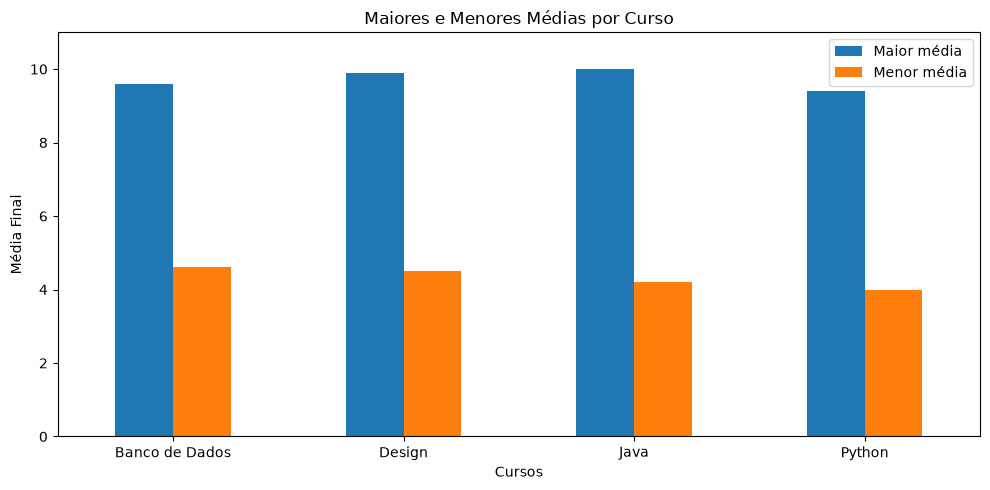

In [10]:
# GRÁFICO 1

medias = df.groupby("Curso")["Media_Final"].agg(["max", "min"])

medias.plot(kind="bar", figsize=(10, 5))

plt.title("Maiores e Menores Médias por Curso")
plt.xlabel("Cursos")
plt.ylabel("Média Final")
plt.legend(["Maior média", "Menor média"])
plt.xticks(rotation=0)
plt.ylim(0, 11)
plt.tight_layout()

plt.savefig("grafico1.png")
plt.show()

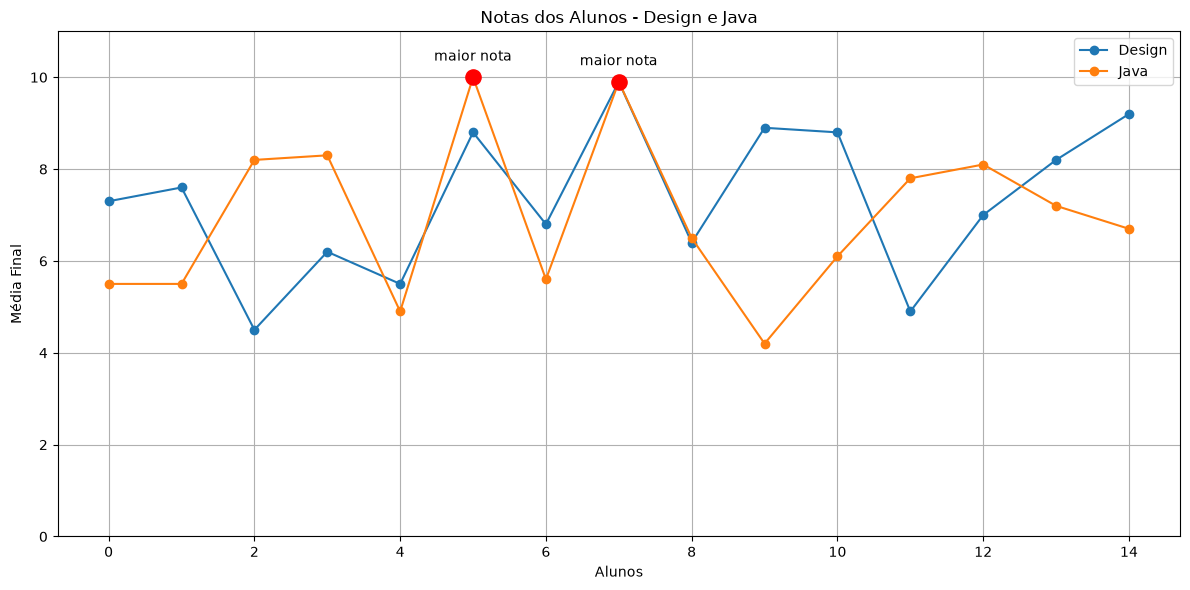

In [11]:
# GRÁFICO 2

design = df[df["Curso"] == "Design"].reset_index(drop=True)
java = df[df["Curso"] == "Java"].reset_index(drop=True)

plt.figure(figsize=(12, 6))

plt.plot(design.index, design["Media_Final"], marker="o", label="Design")
plt.plot(java.index, java["Media_Final"], marker="o", label="Java")

# Identificando as duas maiores notas
maiores = df[df["Curso"].isin(["Design", "Java"])].nlargest(2, "Media_Final")

for _, aluno in maiores.iterrows():
    dados = design if aluno["Curso"] == "Design" else java
    posicao = dados.index[dados["Nome"] == aluno["Nome"]][0]

    plt.scatter(posicao, aluno["Media_Final"], color="red", s=120, zorder=5)

    plt.annotate(
        "maior nota",
        (posicao, aluno["Media_Final"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

plt.title("Notas dos Alunos - Design e Java")
plt.xlabel("Alunos")
plt.ylabel("Média Final")
plt.legend()
plt.grid(True)
plt.ylim(0, 11)
plt.tight_layout()

plt.savefig("grafico2.png")
plt.show()

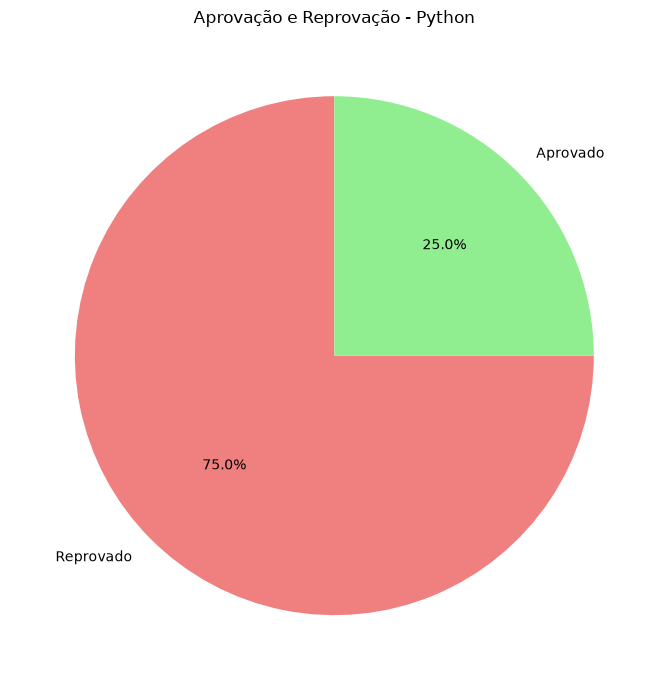

In [12]:
# GRÁFICO 3

python = df[df["Curso"] == "Python"].copy()

python["Situacao"] = python["Media_Final"].apply(
    lambda nota: "Aprovado" if nota >= 7 else "Reprovado"
)

resultado = python["Situacao"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    resultado,
    labels=resultado.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["lightcoral", "lightgreen"] if resultado.index[0] == "Reprovado" else ["lightgreen", "lightcoral"]
)

plt.title("Aprovação e Reprovação - Python")
plt.tight_layout()

plt.savefig("grafico3.png")
plt.show()